# 02. Разведочный анализ (EDA)

Вход — `data/interim/sessions_clean.pkl` из `01_preprocessing.ipynb`: одна строка = один визит.
**Конверсия (CR)** везде — доля визитов, в которых было целевое действие (как в глоссарии брифа).

Вопросы, на которые отвечаем:
1. Как распределены числовые признаки и чем отличаются визиты с конверсией?
2. Какие каналы, устройства и города приводят «горячих» посетителей?
3. Зависит ли конверсия от времени и меняется ли со временем (важно для валидации модели)?
4. Есть ли сильно связанные между собой признаки?

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.float_format', '{:.3f}'.format)
sns.set_theme(style='whitegrid')
root = Path(os.getcwd()).parent

df = pd.read_pickle(root / 'data' / 'interim' / 'sessions_clean.pkl')
CR = df['target'].mean()
print(f'Визитов: {len(df):,}, клиентов: {df["client_id"].nunique():,}, конверсия: {CR:.2%}')
print(f'Период: {df["visit_dt"].min():%Y-%m-%d} → {df["visit_dt"].max():%Y-%m-%d}')

Визитов: 1,732,266, клиентов: 1,320,704, конверсия: 2.90%
Период: 2021-05-19 → 2021-12-31


In [2]:
def cr_table(col, top=15, min_visits=1000):
    t = df.groupby(col)['target'].agg(CR='mean', визитов='size')
    t = t[t['визитов'] >= min_visits].sort_values('визитов', ascending=False).head(top)
    return t.sort_values('CR')

def plot_cr(col, top=15, min_visits=1000, ax=None, title=None):
    t = cr_table(col, top, min_visits)
    ax = ax or plt.gca()
    ax.barh(t.index.astype(str), t['CR'] * 100)
    ax.axvline(CR * 100, color='red', ls='--', label=f'средняя {CR:.1%}')
    ax.set_xlabel('конверсия, %'); ax.set_title(title or f'Конверсия по {col}'); ax.legend(loc='lower right')
    return t

## 1. Числовые признаки

,count,mean,std,min,50%,90%,99%,max
visit_number,1732266.000,2.189,5.045,1.000,1.000,3.000,30.000,50.000
n_hits,1732266.000,14.458,19.595,1.000,8.000,35.000,91.000,500.000
n_pages,1732266.000,1.863,1.404,1.000,1.000,3.000,7.000,45.000
duration_sec,733370.000,144.509,319.220,0.000,29.348,376.152,1614.361,13156.885
screen_w,1732266.000,658.691,555.065,0.000,393.000,1680.000,2560.000,5924.000
screen_h,1732266.000,839.120,187.693,0.000,844.000,1080.000,1440.000,20000.000


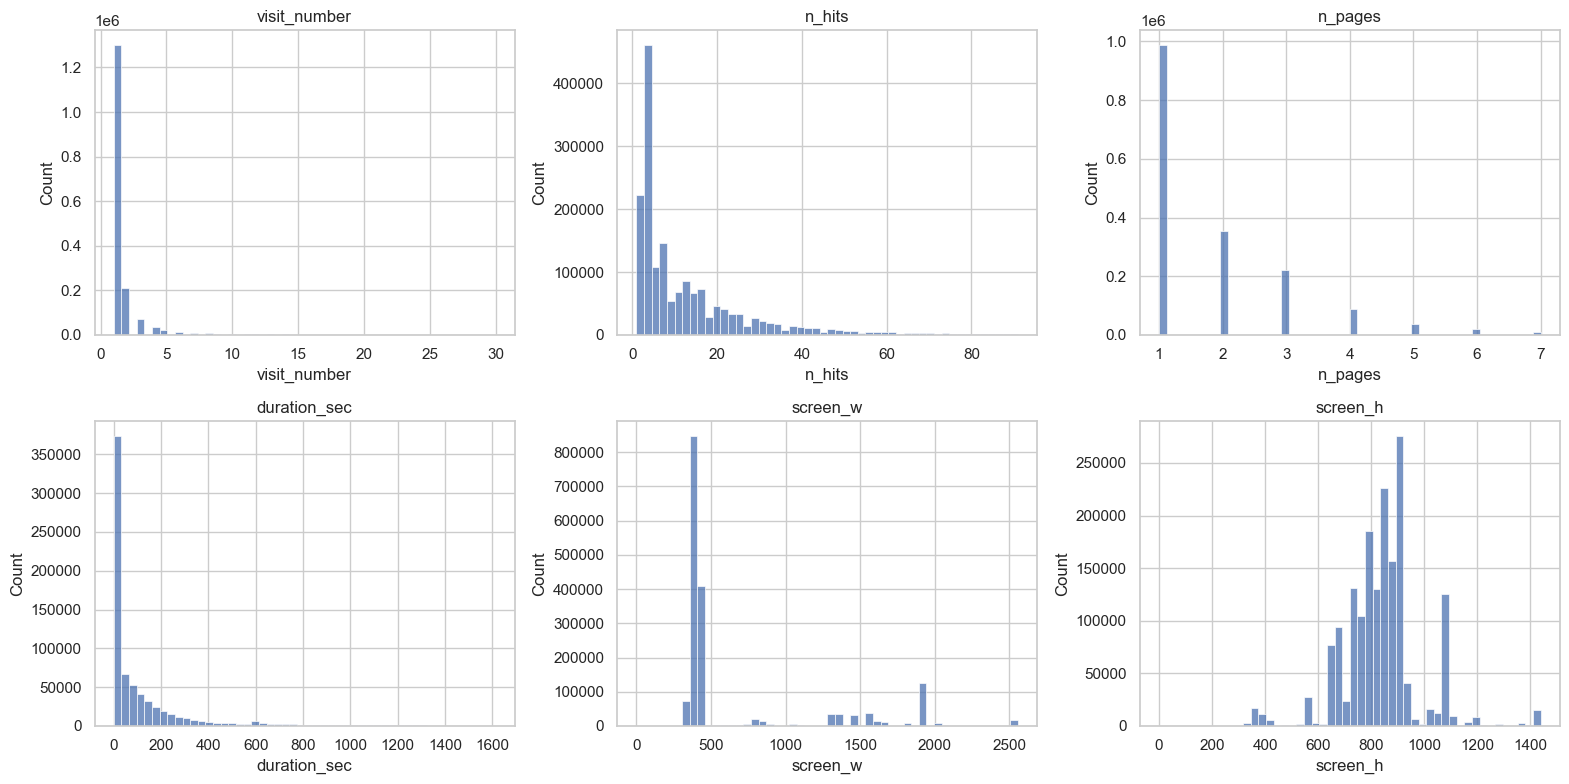

In [3]:
num = ['visit_number', 'n_hits', 'n_pages', 'duration_sec', 'screen_w', 'screen_h']
display(df[num].describe(percentiles=[.5, .9, .99]).T)

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, num):
    x = df[col].dropna()
    x = x[x <= x.quantile(0.99)]  # хвост обрезаем только для наглядности графика, данные не трогаем
    sns.histplot(x, bins=50, ax=ax); ax.set_title(col)
plt.tight_layout(); plt.show()

**Комментарий.** Все поведенческие признаки сильно скошены вправо: у половины визитов 8 событий и одна страница,
у 90% клиентов не больше 3 визитов. Длительность визита неизвестна у 58% визитов — в логах нет времени событий.
Выбросы **не удаляем**: длинные визиты — как раз те посетители, которые оставляют заявки.
Нулевые размеры экрана — редкий мусор GA, их оставляем как есть.

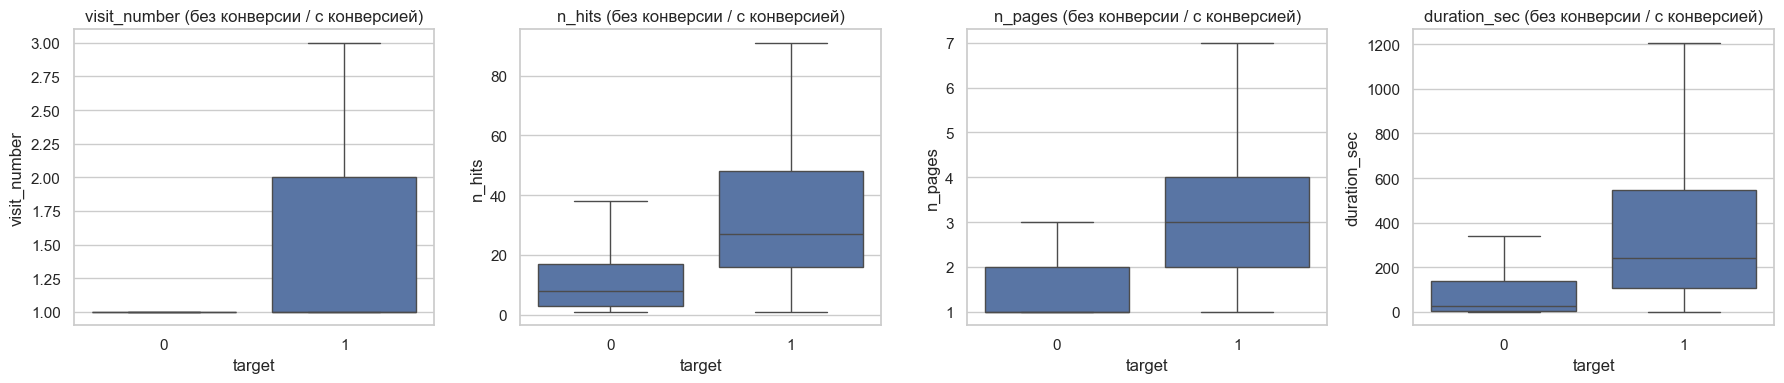

,visit_number,n_hits,n_pages,duration_sec
target,,,,
нет,1.000,8.000,1.000,26.626
есть,1.000,27.000,3.000,240.433


In [4]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ['visit_number', 'n_hits', 'n_pages', 'duration_sec']):
    cap = df[col].quantile(0.99)
    sns.boxplot(data=df.assign(**{col: df[col].clip(upper=cap)}), x='target', y=col, ax=ax, showfliers=False)
    ax.set_title(f'{col} (без конверсии / с конверсией)')
plt.tight_layout(); plt.show()
display(df.groupby('target')[['visit_number', 'n_hits', 'n_pages', 'duration_sec']].median().rename(index={0: 'нет', 1: 'есть'}))

**Комментарий.** Визиты с конверсией заметно «глубже»: медиана 27 событий против 8, 3 страницы против 1,
около 4 минут против 27 секунд. Логично — заявку оставляет тот, кто изучил каталог. Номер визита по медиане одинаковый
(у большинства это первый визит), но конверсия растёт с номером визита — см. раздел 3.

> `n_hits`, `n_pages`, `duration_sec` известны только после визита, поэтому **в модель не идут** —
> они здесь, чтобы понять поведение посетителей.

## 2. Каналы трафика

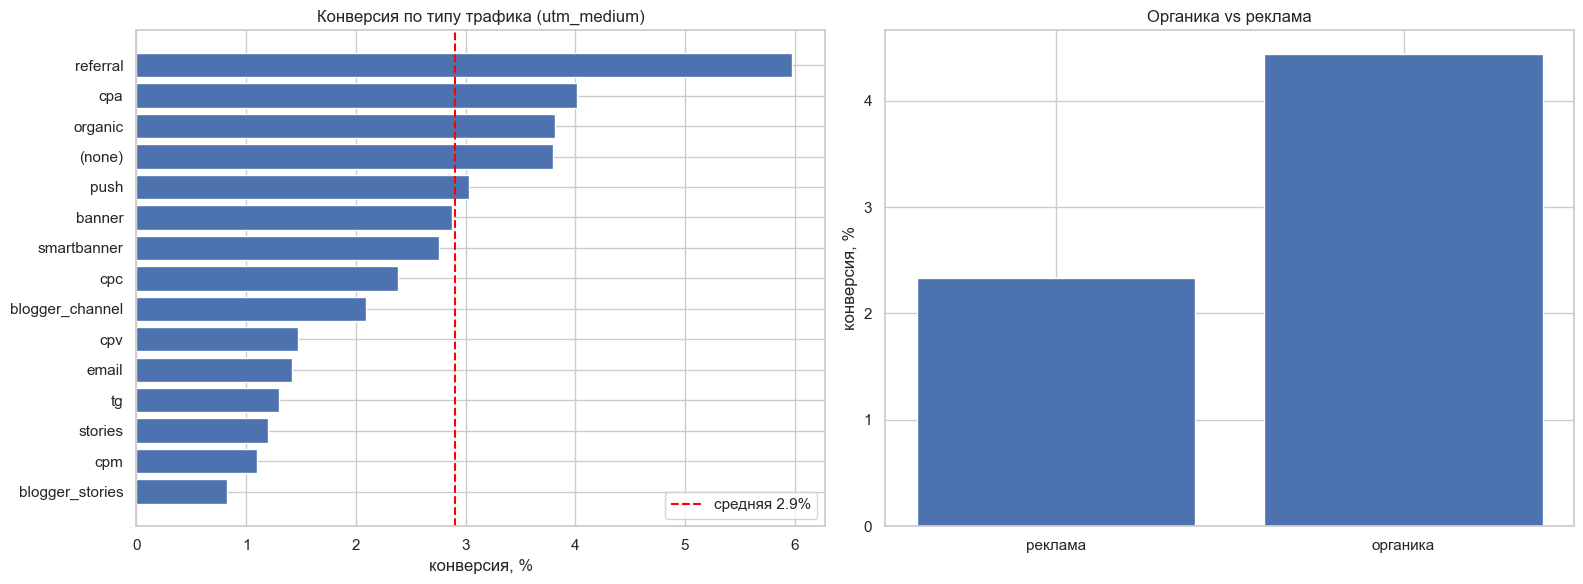

,CR,визитов
utm_medium,,
referral,0.060,136851
cpa,0.040,3266
organic,0.038,55009
(none),0.038,277060
push,0.030,27710
banner,0.029,525206
smartbanner,0.028,6501
cpc,0.024,399395
blogger_channel,0.021,7731


,CR,визитов
is_organic,,
реклама,0.023,1263346
органика,0.044,468920


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
t_medium = plot_cr('utm_medium', top=15, min_visits=3000, ax=axes[0], title='Конверсия по типу трафика (utm_medium)')
t_org = df.groupby('is_organic')['target'].agg(CR='mean', визитов='size').rename(index={0: 'реклама', 1: 'органика'})
axes[1].bar(t_org.index, t_org['CR'] * 100); axes[1].set_title('Органика vs реклама'); axes[1].set_ylabel('конверсия, %')
plt.tight_layout(); plt.show()
display(t_medium.sort_values('CR', ascending=False)); display(t_org)

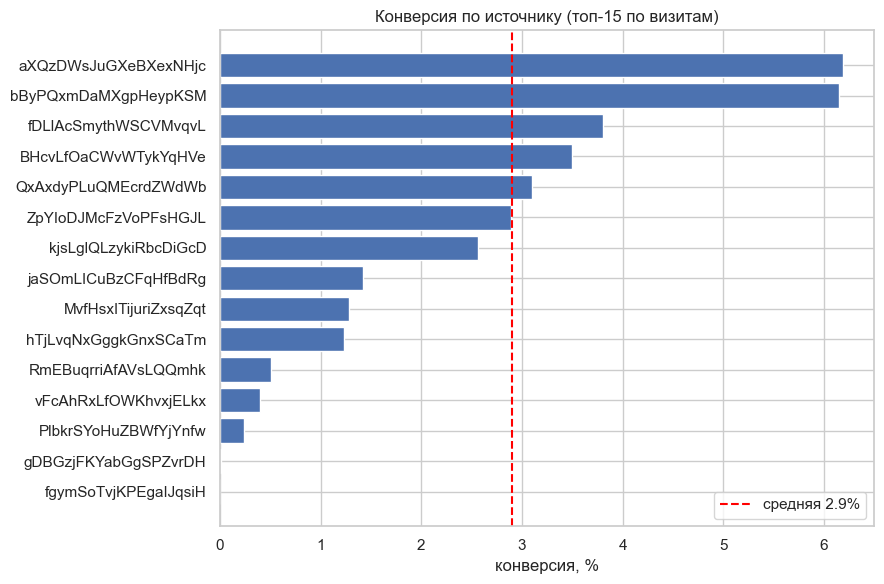

In [6]:
plt.figure(figsize=(9, 6))
t_source = plot_cr('utm_source', top=15, min_visits=5000, title='Конверсия по источнику (топ-15 по визитам)')
plt.tight_layout(); plt.show()

**Комментарий.** Канал — один из главных факторов конверсии.
- **Органика конвертирует почти вдвое лучше рекламы**: 4,4% против 2,3%. Лучший тип трафика — `referral` (6,0%),
  дальше `organic` и `(none)` (3,8%).
- Среди платных: `push` 3,0%, `banner` 2,9%, `cpc` 2,4%. Хуже всех — `cpm` (1,1%), `stories` (1,2%), `tg` (1,3%),
  `email` (1,4%), `blogger_stories` (0,8%); при этом на `cpm` приходится 230 тыс. визитов.
- По источникам разброс ещё сильнее: два источника дают ~6% (вдвое выше средней), несколько крупных — почти 0%.

## 3. Посетитель и устройство

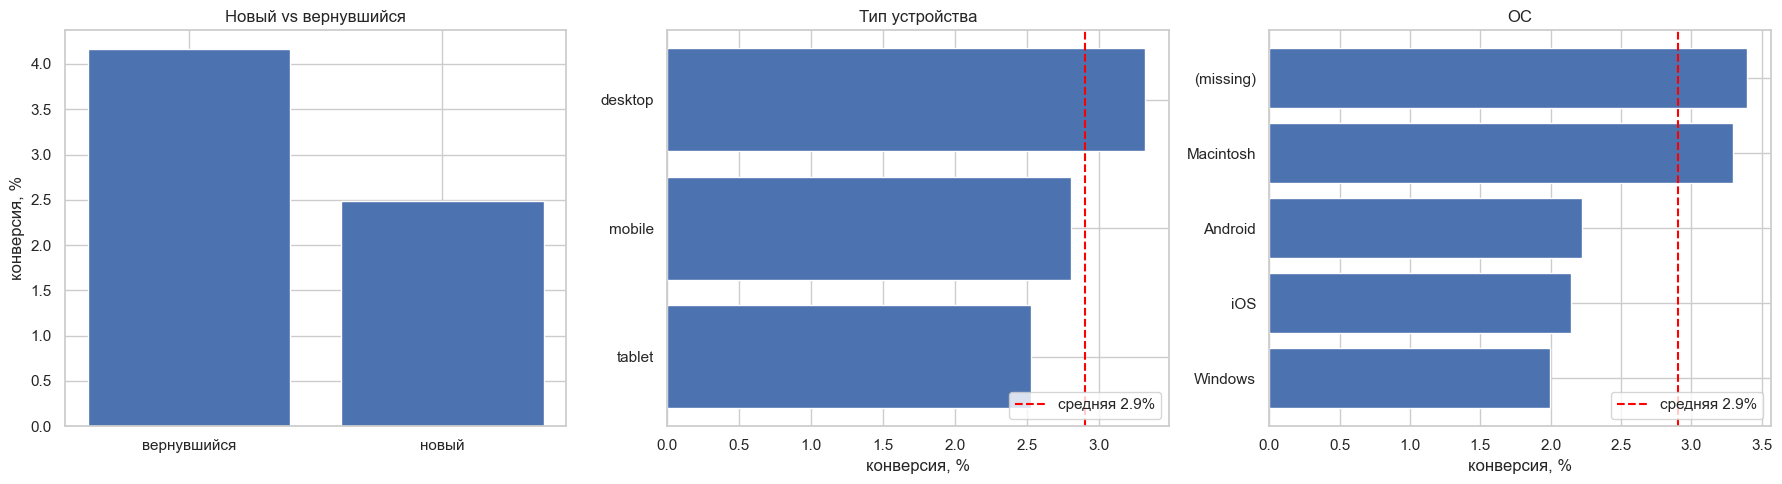

,CR,визитов
is_new_visitor,,
вернувшийся,0.042,431167
новый,0.025,1301099


,CR,визитов
device_category,,
tablet,0.025,16696
mobile,0.028,1368679
desktop,0.033,346891


,CR,визитов
device_os,,
Windows,0.020,81740
iOS,0.021,182597
Android,0.022,425520
Macintosh,0.033,23415
(missing),0.034,1014273


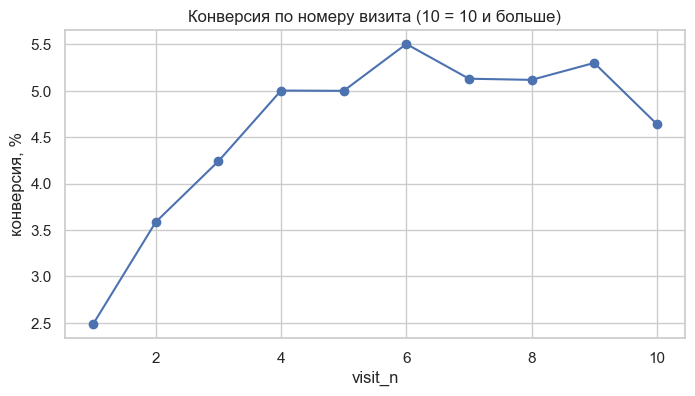

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
t_new = df.groupby('is_new_visitor')['target'].agg(CR='mean', визитов='size').rename(index={0: 'вернувшийся', 1: 'новый'})
axes[0].bar(t_new.index, t_new['CR'] * 100); axes[0].set_title('Новый vs вернувшийся'); axes[0].set_ylabel('конверсия, %')
t_dev = plot_cr('device_category', ax=axes[1], title='Тип устройства')
t_os = plot_cr('device_os', top=8, min_visits=5000, ax=axes[2], title='ОС')
plt.tight_layout(); plt.show()
display(t_new, t_dev, t_os)

vn = df.assign(visit_n=df['visit_number'].clip(upper=10)).groupby('visit_n')['target'].mean() * 100
vn.plot(marker='o', figsize=(8, 4), title='Конверсия по номеру визита (10 = 10 и больше)', ylabel='конверсия, %'); plt.show()

**Комментарий.**
- **Вернувшиеся посетители конвертируют в 1,7 раза лучше новых** (4,2% против 2,5%). Конверсия растёт с номером визита:
  2,5% на первом → 4,2% на третьем → 5–5,5% к 4–6-му визиту, дальше плато.
- Десктоп (3,3%) лучше мобильных (2,8%) и планшетов (2,5%).
- По ОС: Macintosh 3,3%, Android, iOS и Windows — 2,0–2,2%. У 58% визитов ОС не определена, и у них конверсия 3,4% —
  пропуск сам по себе информативен (зависит от источника трафика), поэтому держим его отдельной категорией, а не заполняем модой.

## 4. География

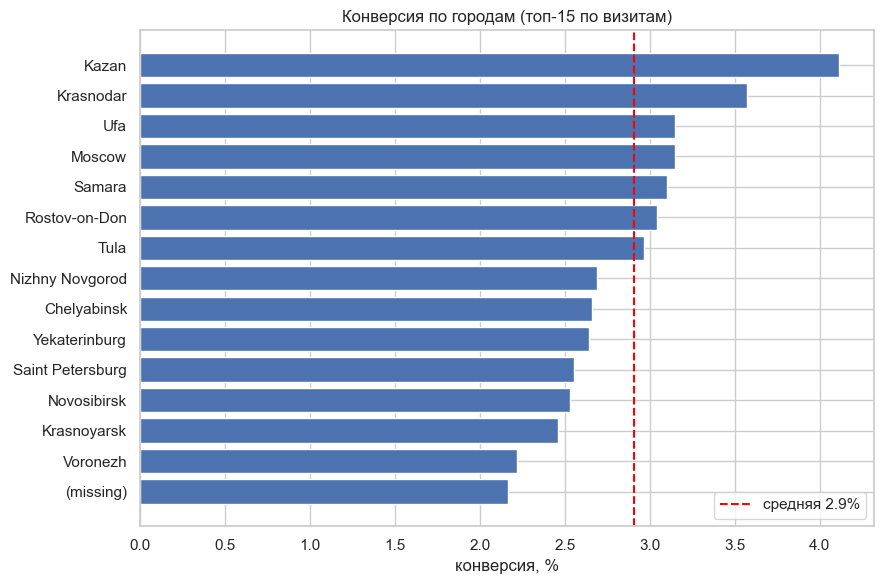

In [8]:
plt.figure(figsize=(9, 6))
t_city = plot_cr('geo_city', top=15, min_visits=5000, title='Конверсия по городам (топ-15 по визитам)')
plt.tight_layout(); plt.show()

**Комментарий.** Выше средней — Казань (~4,1%), Краснодар (~3,6%), Уфа и Москва (~3,2%); ниже — Петербург (~2,5%),
Новосибирск, Красноярск, Воронеж (2,2–2,5%). Разница между городами заметно меньше, чем между каналами.

## 5. Время визита и динамика

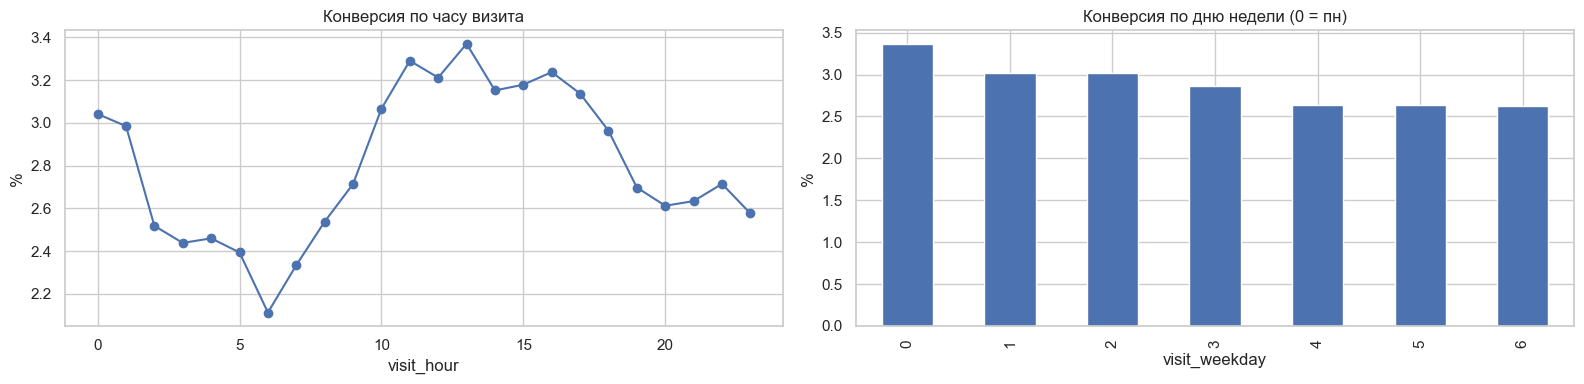

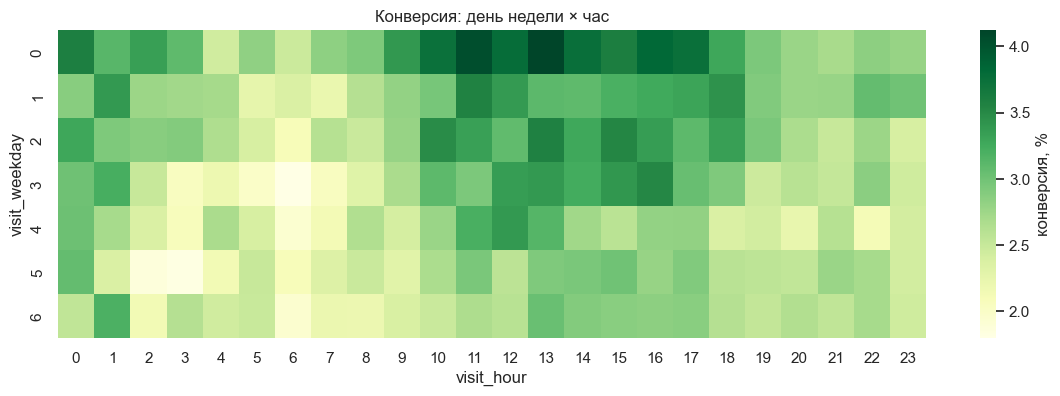

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
(df.groupby('visit_hour')['target'].mean() * 100).plot(ax=axes[0], marker='o', title='Конверсия по часу визита', ylabel='%')
(df.groupby('visit_weekday')['target'].mean() * 100).plot.bar(ax=axes[1], title='Конверсия по дню недели (0 = пн)', ylabel='%')
plt.tight_layout(); plt.show()

heat = df.pivot_table(index='visit_weekday', columns='visit_hour', values='target', aggfunc='mean') * 100
plt.figure(figsize=(14, 4)); sns.heatmap(heat, cmap='YlGn', cbar_kws={'label': 'конверсия, %'})
plt.title('Конверсия: день недели × час'); plt.show()

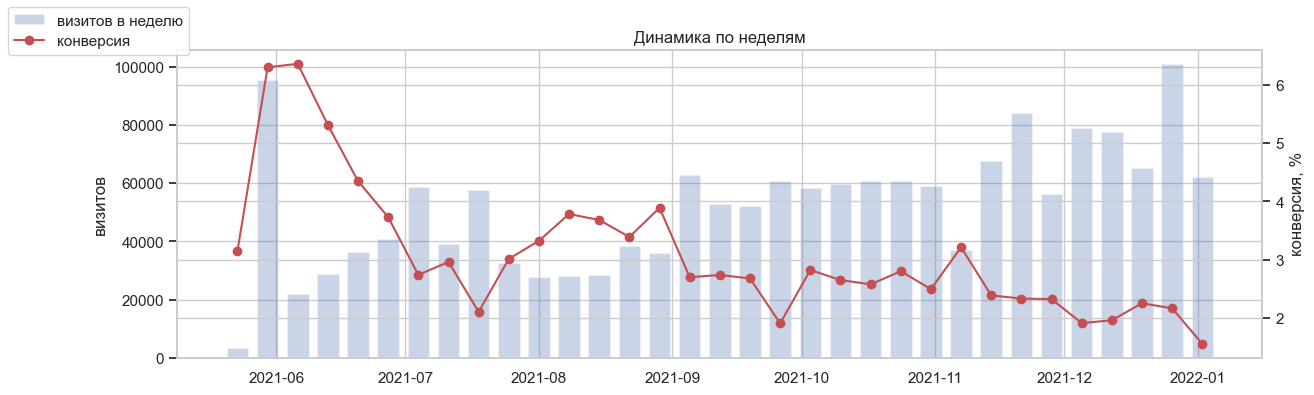

,CR,визитов
visit_dt,,
2021-05,0.061,104591
2021-06,0.041,160622
2021-07,0.028,174708
2021-08,0.035,155003
2021-09,0.025,243803
2021-10,0.027,263459
2021-11,0.024,263835
2021-12,0.020,366245


In [10]:
weekly = df.set_index('visit_dt').resample('W')['target'].agg(['mean', 'size'])
fig, ax1 = plt.subplots(figsize=(14, 4))
ax1.bar(weekly.index, weekly['size'], width=5, alpha=.3, label='визитов в неделю'); ax1.set_ylabel('визитов')
ax2 = ax1.twinx(); ax2.plot(weekly.index, weekly['mean'] * 100, color='C3', marker='o', label='конверсия')
ax2.set_ylabel('конверсия, %'); plt.title('Динамика по неделям'); fig.legend(loc='upper left'); plt.show()

monthly = df.groupby(df['visit_dt'].dt.to_period('M'))['target'].agg(CR='mean', визитов='size')
monthly

**Комментарий.**
- **Время суток:** пик — днём, 11–17 ч (3,2–3,4%), минимум — ранним утром, 5–7 ч (2,1–2,4%).
- **День недели:** лучше всего понедельник (3,3%), к выходным конверсия снижается до ~2,6%.
  На тепловой карте самые «горячие» клетки — будние дни с 10 до 17.
- **Динамика:** трафик растёт (105 тыс. визитов в мае → 366 тыс. в декабре), а **конверсия падает: 6,1% в мае → 2,0% в декабре**.
  Скорее всего, растёт доля менее целевого рекламного трафика. Это **дрейф данных**: модель, обученная на прошлом,
  будет хуже работать на будущих месяцах — поэтому в `03_model` есть отдельная проверка по времени.

## 6. Связь признаков между собой

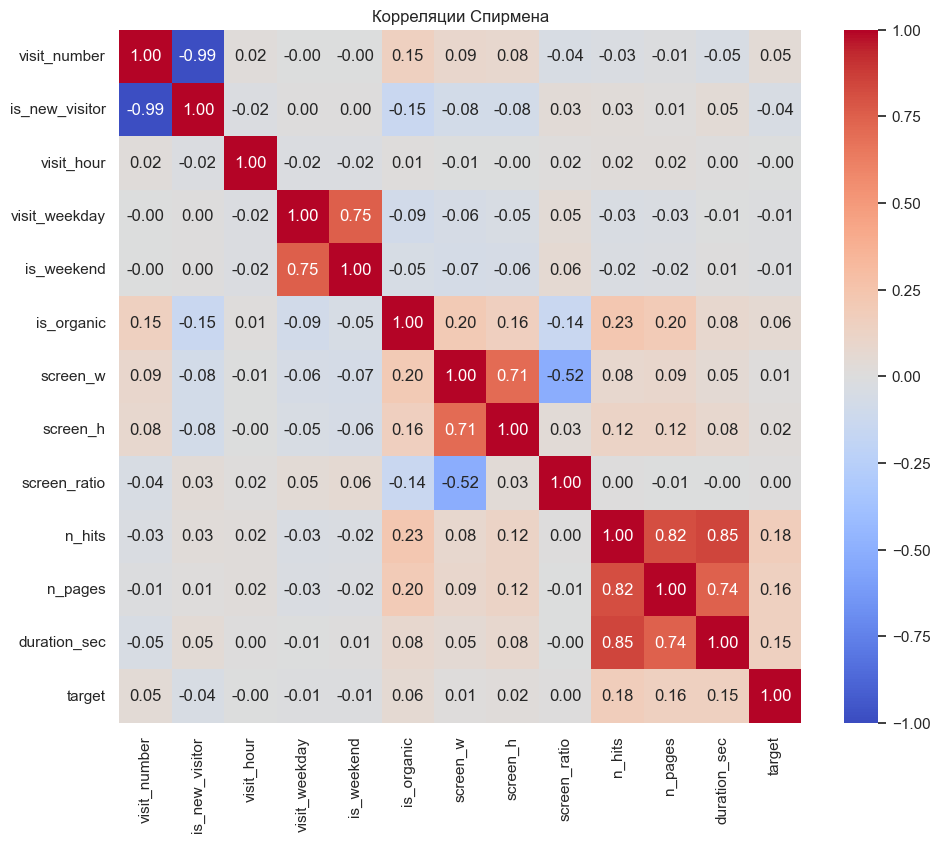

ρ
visit_number  is_new_visitor -0.988
n_hits        duration_sec    0.849
              n_pages         0.820
visit_weekday is_weekend      0.751
n_pages       duration_sec    0.742
screen_w      screen_h        0.707

In [11]:
cols = ['visit_number', 'is_new_visitor', 'visit_hour', 'visit_weekday', 'is_weekend', 'is_organic',
        'screen_w', 'screen_h', 'screen_ratio', 'n_hits', 'n_pages', 'duration_sec', 'target']
corr = df[cols].corr(method='spearman')
plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Корреляции Спирмена'); plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
display(pairs[pairs.abs() > 0.7].sort_values(key=abs, ascending=False).to_frame('ρ'))

**Комментарий.** Почти дублируют друг друга `visit_number` и `is_new_visitor` (ρ = −0,99), заметно связаны
`visit_weekday`/`is_weekend` (0,75) и ширина/высота экрана (0,71). Для бустинга это не проблема,
в логистической регрессии влияние дублей смягчает регуляризация. Поведенческие показатели (`n_hits`, `n_pages`,
`duration_sec`) сильно связаны между собой (0,74–0,85), но в модель они не идут.

## Выводы EDA
1. **Конверсия низкая — 2,9%**, классы сильно несбалансированы → метрика ROC-AUC, порог для ответа 0/1 подбираем отдельно.
2. **Главное — откуда пришёл посетитель:** органика и рефералы конвертируют в 1,5–2 раза лучше рекламы;
   худшие платные каналы — cpm, stories, email, tg.
3. **Вернувшиеся посетители** конвертируют в 1,7 раза лучше новых — номер визита важный признак.
4. Устройство, город, время суток и день недели влияют, но слабее канала.
5. **Конверсия падает со временем** (6,1% → 2,0%) — модель надо проверять на будущих датах, а в продакшене
   регулярно переобучать на свежих данных.
6. Для модели берём только признаки, известные в начале визита (`src/features.py`); поведенческие показатели — только для анализа.